In [8]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import time
import joblib
import pandas as pd

from src.constants import ACTIONS


In [3]:
model = joblib.load('exercise_model.pkl')
scaler = joblib.load('scaler.pkl')

In [7]:
# Shuffle the DataFrame
df = pd.read_csv('./data/angled_data.csv')
df = df.sample(frac=1).reset_index(drop=True)



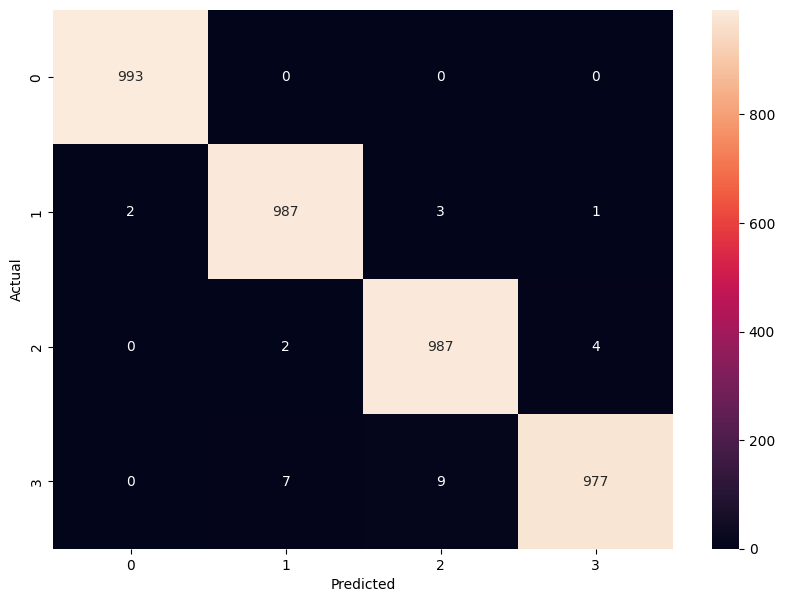

In [11]:
#create a confunctio matrix of the model

def get_confusion_matrix(model, X, y):
    y_pred = model.predict(X)
    confusion_matrix = np.zeros((len(ACTIONS), len(ACTIONS)))
    for i in range(len(y_pred)):
        confusion_matrix[y[i]][y_pred[i]] += 1
    return confusion_matrix

# Get the confusion matrix

X = df.drop('label', axis=1)
y = df['label']
X = scaler.transform(X)
confusion_matrix = get_confusion_matrix(model, X, y)


#plot the confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
sns.heatmap(confusion_matrix, annot=True, fmt='g', color
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


